In [92]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [93]:
df = pd.read_csv("r-ecommerce_Cleaned.csv")

# 1. Build daily and monthly gross sales, net sales, units, discounts, taxes, and refunds by product and channel.

Convert date and numbers

In [94]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

cols = ["Qty", "Unit_Price", "Discount", "Tax", "Refund_Amount"]
df[cols] = df[cols].apply(pd.to_numeric, errors="coerce").fillna(0)

Daily Sales Report


,Date,Product,Sales_Channel,Currency,Gross_Sales,Net_Sales,Qty,Discount,Tax,Refund_Amount
0,2026-01-03,Yoga Mat,Online,INR,0.0,-89.9,1.0,89.9,145.64,0.00
1,2026-02-03,LED Desk Lamp,Mobile App,INR,11988.0,11988.0,12.0,0.0,2157.84,0.00
2,2026-02-06,Smart Fitness Watch,Marketplace,INR,0.0,0.0,1.0,0.0,809.82,0.00
3,2026-02-08,LED Desk Lamp,Mobile_App,INR,0.0,0.0,1.0,0.0,179.82,0.00
4,2026-03-01,A5 Notebook,Marketplace,USD,2.0,2.0,1.0,0.0,0.16,0.65


Monthly Sales Report


,Month,Product,Sales_Channel,Currency,Gross_Sales,Net_Sales,Qty,Discount,Tax,Refund_Amount
0,2026-01,Yoga Mat,Online,INR,0.0,-89.9,1.0,89.9,145.64,0.00
1,2026-02,LED Desk Lamp,Mobile App,INR,11988.0,11988.0,12.0,0.0,2157.84,0.00
2,2026-02,LED Desk Lamp,Mobile_App,INR,0.0,0.0,1.0,0.0,179.82,0.00
3,2026-02,Smart Fitness Watch,Marketplace,INR,0.0,0.0,1.0,0.0,809.82,0.00
4,2026-03,A5 Notebook,Marketplace,USD,2.0,2.0,1.0,0.0,0.16,0.65


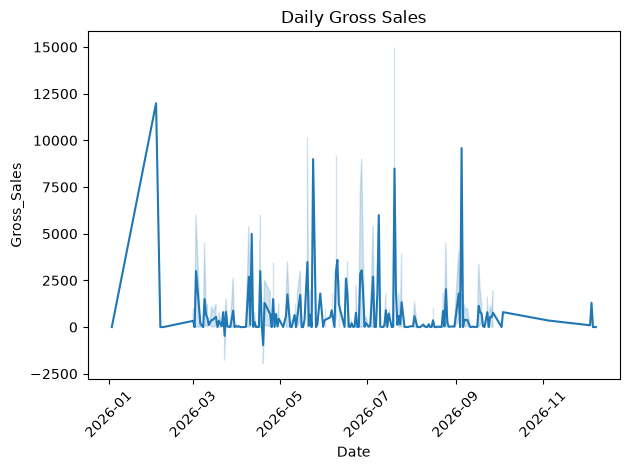

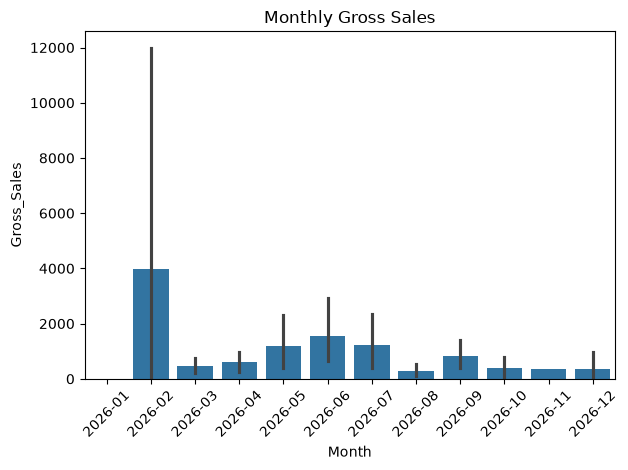

In [95]:
#Calculate sales
df["Gross_Sales"] = df["Qty"] * df["Unit_Price"]
df["Net_Sales"] = df["Gross_Sales"] - df["Discount"]

# Create month
df["Month"] = df["Date"].dt.strftime("%Y-%m")

#Create daily report
daily_report = df.groupby(
    ["Date", "Product", "Sales_Channel", "Currency"], dropna=False
).agg({
    "Gross_Sales": "sum",
    "Net_Sales": "sum",
    "Qty": "sum",
    "Discount": "sum",
    "Tax": "sum",
    "Refund_Amount": "sum"}).reset_index()

#Create monthly report
monthly_report = df.groupby(
    ["Month", "Product", "Sales_Channel", "Currency"], dropna=False
).agg({
    "Gross_Sales": "sum",
    "Net_Sales": "sum",
    "Qty": "sum",
    "Discount": "sum",
    "Tax": "sum",
    "Refund_Amount": "sum"
}).reset_index()

#Show reports
print("Daily Sales Report")
display(daily_report.head())

print("Monthly Sales Report")
display(monthly_report.head())

#Draw daily sales chart
sns.lineplot(data=daily_report, x="Date", y="Gross_Sales")
plt.title("Daily Gross Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#Draw monthly sales chart
sns.barplot(data=monthly_report, x="Month", y="Gross_Sales")
plt.title("Monthly Gross Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




# 2.Calculate average order value, items per order, and revenue per visitor.

In [96]:
# Calculate total value for each order
df["Order_Value"] = df["Qty"] * df["Unit_Price"] - df["Discount"]

# Average Order Value (AOV)
aov = df.groupby("Order_ID")["Order_Value"].sum().mean()

# Items per Order
items_per_order = df.groupby("Order_ID")["Qty"].sum().mean()

print("Average Order Value:", round(aov, 2))
print("Items per Order:", round(items_per_order, 2))

# Revenue per Visitor
revenue = df["Order_Value"].sum()
visitors = df["Visitor_ID"].nunique()

revenue_per_visitor = revenue / visitors if visitors > 0 else 0

print("Revenue per Visitor:", round(revenue_per_visitor, 2))


Average Order Value: 1315.62
Items per Order: 13.41
Revenue per Visitor: 1335.14


# 3. Create customer cohorts by first purchase month and calculate repeat-purchase rates.

,Total_Customers,Repeat_Customers,Repeat_Rate
First_Purchase_Month,,,
2026-02,1,1,100.00
2026-03,19,8,42.11
2026-04,14,6,42.86
2026-05,5,2,40.00
2026-06,10,3,30.00
2026-07,10,2,20.00
2026-08,8,1,12.50
2026-09,8,1,12.50


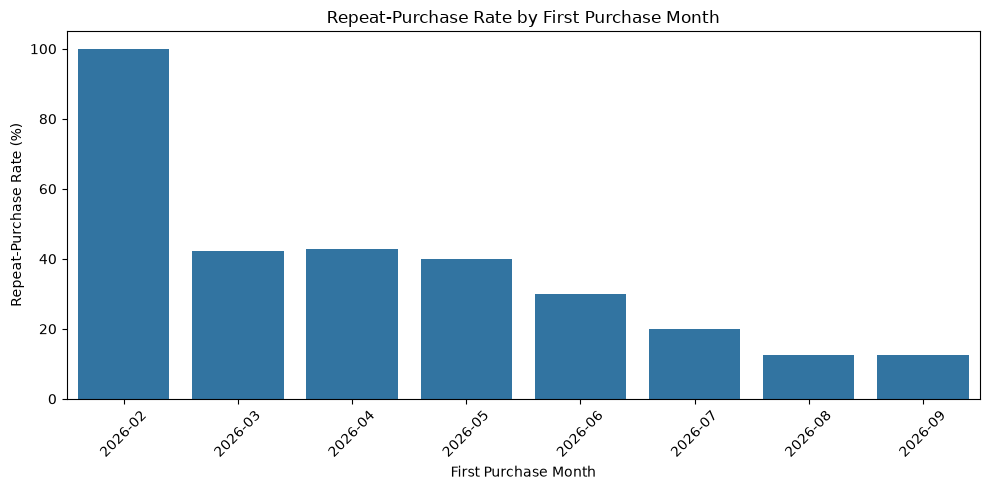

In [97]:
# Keep purchase records only
df = df[df["Event_Type"] == "purchase"].copy()

# Convert date
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Remove missing values
df = df.dropna(subset=["Customer_ID", "Order_ID", "Date"])

# Find first purchase month for each customer
df["First_Purchase_Month"] = df.groupby("Customer_ID")["Date"].transform("min").dt.to_period("M")

# Count unique orders per customer
customer_orders = df.groupby("Customer_ID")["Order_ID"].nunique()

# Identify repeat customers
repeat_customers = customer_orders[customer_orders > 1].index

# Create cohort table
cohorts = df.groupby("First_Purchase_Month").agg(
    Total_Customers=("Customer_ID", "nunique")
)

cohorts["Repeat_Customers"] = df[
    df["Customer_ID"].isin(repeat_customers)
].groupby("First_Purchase_Month")["Customer_ID"].nunique()

cohorts["Repeat_Customers"] = cohorts["Repeat_Customers"].fillna(0)

# Calculate repeat-purchase rate
cohorts["Repeat_Rate"] = (
    np.where(
        cohorts["Total_Customers"] > 0,
        cohorts["Repeat_Customers"] / cohorts["Total_Customers"] * 100,
        0
    )
).round(2)

# Display results
display(cohorts)

# Plot repeat-purchase rate
plt.figure(figsize=(10, 5))
sns.barplot(x=cohorts.index.astype(str), y=cohorts["Repeat_Rate"])
plt.title("Repeat-Purchase Rate by First Purchase Month")
plt.xlabel("First Purchase Month")
plt.ylabel("Repeat-Purchase Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 4.Measure conversion funnel from session to cart, checkout, payment, and completed order.

Remove rows without Session_ID

In [98]:
df = df.dropna(subset=["Session_ID"])

Count unique sessions

In [99]:
total_sessions = df["Session_ID"].nunique()

In [100]:
# Count sessions at each stage
checkout = df[df["Event_Type"] == "checkout_complete"]["Session_ID"].nunique()

payment = df[df["Event_Type"] == "payment_success"]["Session_ID"].nunique()

completed = df[df["Event_Type"].isin(["order_completed", "purchase"])]["Session_ID"].nunique()

# Create the conversion funnel
funnel = pd.DataFrame({
    "Stage": ["Session", "Cart", "Checkout", "Payment", "Completed Order"],
    "Total Sessions": [total_sessions, None, checkout, payment, completed]})

# Calculate conversion percentage
funnel["Conversion (%)"] = (
    funnel["Total Sessions"] / funnel["Total Sessions"].shift(1) * 100
)

funnel.loc[0, "Conversion (%)"] = 100



In [101]:
display(funnel.round(2))

,Stage,Total Sessions,Conversion (%)
0,Session,100.0,100.0
1,Cart,NaN,NaN
2,Checkout,0.0,NaN
3,Payment,0.0,NaN
4,Completed Order,100.0,inf


# 5. Calculate promotion redemption, incremental sales, and discount cost by campaign.

,Campaign_ID,Total_Orders,Promotions_Redeemed,Total_Sales,Discount_Cost,Redemption_Rate (%)
0,CMP-001,13,3,10264.24,171.66,23.08
1,CMP-002,2,0,3361.88,149.95,0.00
2,CMP-003,5,0,3285.17,669.60,0.00
3,CMP-004,6,1,11842.88,511.85,16.67
4,CMP-005,1,1,423.74,0.00,100.00
5,CMP-006,2,1,114.70,0.00,50.00
6,CMP-007,5,4,7946.00,132.05,80.00


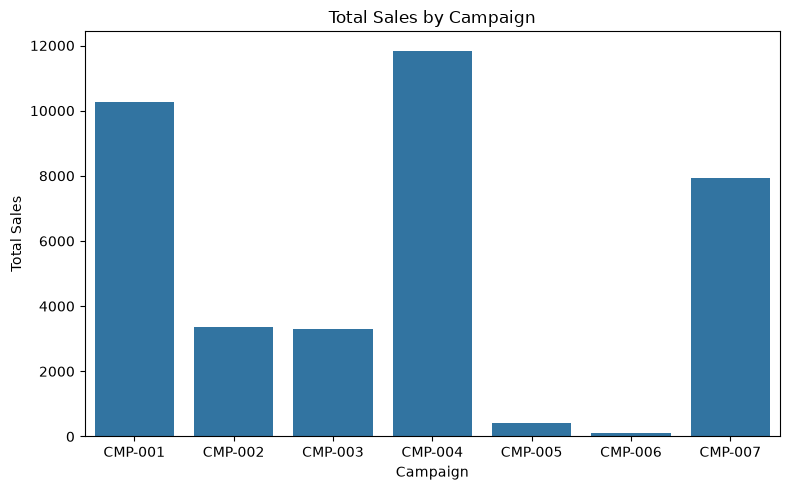

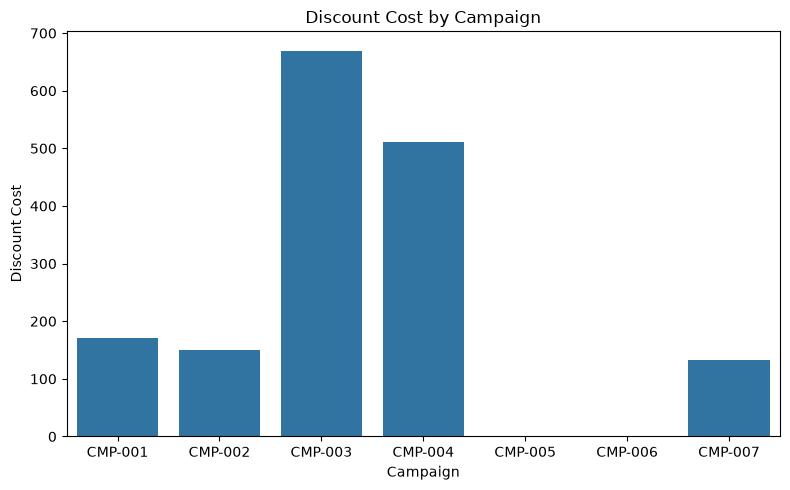

In [102]:



# Keep rows where a campaign is available
df = df.dropna(subset=["Campaign_ID"])

# Calculate promotion redemption and sales by campaign
result = df.groupby("Campaign_ID").agg(
    Total_Orders=("Order_ID", "nunique"),
    Promotions_Redeemed=("Promotion_Status",
                         lambda x: (x == "applied").sum()),
    Total_Sales=("Amount", "sum"),
    Discount_Cost=("Discount", "sum")
).reset_index()

# Calculate redemption rate
result["Redemption_Rate (%)"] = (
    result["Promotions_Redeemed"] /
    result["Total_Orders"].replace(0, np.nan) * 100
).fillna(0).round(2)

# Show the result
display(result)

# Plot campaign sales
plt.figure(figsize=(8, 5))
sns.barplot(data=result, x="Campaign_ID", y="Total_Sales")
plt.title("Total Sales by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

# Plot discount cost
plt.figure(figsize=(8, 5))
sns.barplot(data=result, x="Campaign_ID", y="Discount_Cost")
plt.title("Discount Cost by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Discount Cost")
plt.tight_layout()
plt.show()


# 6. Build product/category sales rankings and contribution-to-revenue metrics

In [103]:
df = df[df["Event_Type"] == "purchase"]

df.head()

,Order_ID,Line_ID,Event_Version,Customer_ID,Master_Customer_ID,Transaction_ID,Visitor_ID,Session_ID,Event_Type,Order_TS,...,Supplier_Review,Inventory_Review,Event_Review,Shipment_Review,Delivery_Review,Gross_Sales,Net_Sales,Month,Order_Value,First_Purchase_Month
18,ORD-1228,L1,1,CUST-037,CUST-037,TXN-46643560,VIS-47918,SES-353052,purchase,2026-07-20 21:19:00+00:00,...,False,False,False,False,False,-0.0,-599.8,2026-07,-599.8,2026-07
19,ORD-1091,L1,1,CUST-066,CUST-066,TXN-78644309,VIS-37991,SES-603724,purchase,2026-03-03 09:56:00+00:00,...,False,True,False,False,False,0.0,0.0,2026-03,0.0,2026-03
28,ORD-1034,L1,1,CUST-045,CUST-045,TXN42707660,VIS-16648,SES-565198,purchase,2026-04-12 20:49:00+00:00,...,False,False,False,False,False,0.0,-99.9,2026-04,-99.9,2026-04
30,ORD-1187,L2,1,CUST-020,NaN,TXN-15026701,VIS-58102,SES-414786,purchase,2026-03-19 02:25:00+00:00,...,False,False,False,False,False,799.0,799.0,2026-03,799.0,2026-03
36,ORD-1096,L3,1,CUST-120,NaN,TXN43948523,VIS-69151,SES-218877,purchase,2026-04-01 00:15:00+00:00,...,False,False,True,False,False,24.0,24.0,2026-04,24.0,2026-04


In [104]:
product_sales = df.groupby("Product")["Amount"].sum()

product_sales = product_sales.sort_values(ascending=False)

print(product_sales)

Product
Wireless Earbuds Pro      13270.94
Cotton Tee M              11690.97
Slim Fit Jeans 32          7854.44
Cotton Tee L               1744.22
LED Desk Lamp              1060.94
Phone Case X                448.04
Socks 3 Pack                329.46
Gel Pen Pack                271.20
Running Shoes Size 9        255.65
A5 Notebook                 159.30
Smart Fitness Watch         114.70
Yoga Mat                     25.92
Water Bottle Steel 1 L        7.87
Black Ceramic Mug             4.96
Name: Amount, dtype: float64


In [105]:
total_sales = product_sales.sum()

contribution = (product_sales / total_sales) * 100

print(contribution.round(2))

Product
Wireless Earbuds Pro      35.64
Cotton Tee M              31.39
Slim Fit Jeans 32         21.09
Cotton Tee L               4.68
LED Desk Lamp              2.85
Phone Case X               1.20
Socks 3 Pack               0.88
Gel Pen Pack               0.73
Running Shoes Size 9       0.69
A5 Notebook                0.43
Smart Fitness Watch        0.31
Yoga Mat                   0.07
Water Bottle Steel 1 L     0.02
Black Ceramic Mug          0.01
Name: Amount, dtype: float64


In [106]:
category_sales = df.groupby("Product_Category")["Amount"].sum()

category_sales = category_sales.sort_values(ascending=False)

print(category_sales)

Product_Category
Apparel           21619.09
Electronics       13385.64
Home & Kitchen     1073.77
Accessories         448.04
Stationery          430.50
Footwear            255.65
Sports               25.92
Name: Amount, dtype: float64


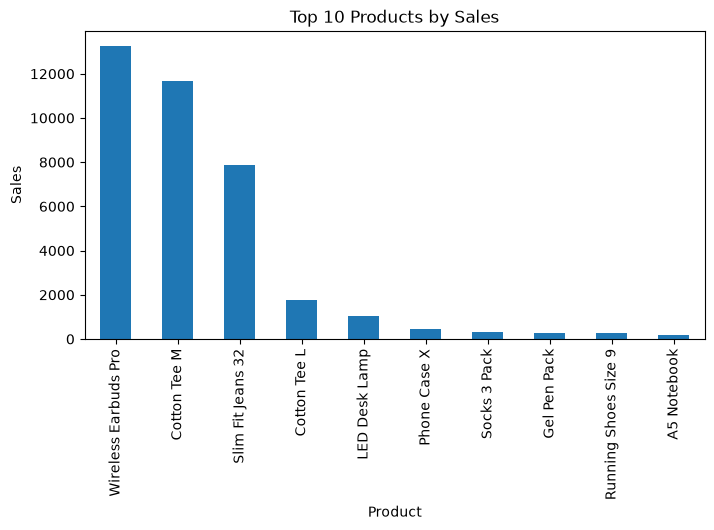

In [107]:
product_sales.head(10).plot(kind="bar", figsize=(8, 4))

plt.title("Top 10 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.show()

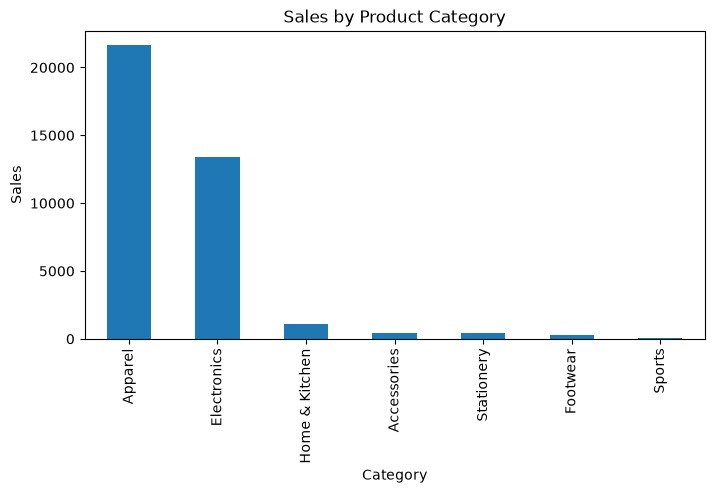

In [108]:
category_sales.plot(kind="bar", figsize=(8, 4))

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.show()

# 7. Calculate return rate and refund value by SKU, supplier, and reason.

In [109]:
returns = df[df["Status"] == "return"]

returns.head()

,Order_ID,Line_ID,Event_Version,Customer_ID,Master_Customer_ID,Transaction_ID,Visitor_ID,Session_ID,Event_Type,Order_TS,...,Supplier_Review,Inventory_Review,Event_Review,Shipment_Review,Delivery_Review,Gross_Sales,Net_Sales,Month,Order_Value,First_Purchase_Month
39,ORD-1129,L1,1,CUST-111,NaN,TXN-40858901,VIS-48034,SES-498281,purchase,2026-04-17 11:22:00+00:00,...,False,False,False,False,False,0.0,0.00,2026-04,0.00,2026-04
96,ORD-1061,L2,1,CUST-092,CUST-092,TXN-25248056,VIS-11958,SES-943816,purchase,2026-08-03 02:09:00+00:00,...,False,False,False,False,False,0.0,-149.95,2026-08,-149.95,2026-08
225,ORD-1215,L1,1,CUST-041,CUST-041,TXN-50621672,VIS-88489,SES-821583,purchase,2026-03-22 22:33:00+00:00,...,False,False,False,False,False,799.0,679.15,2026-03,679.15,2026-03
370,ORD-1045,L1,2,CUST-085,CUST-085,TXN-56541891,VIS-49669,SES-514184,purchase,2026-09-25 19:23:00+00:00,...,False,False,True,False,False,0.0,0.00,2026-09,0.00,2026-09
378,ORD-1250,L3,2,CUST-028,CUST-028,TXN84890137,VIS-68232,SES-621882,purchase,2026-06-19 14:23:00+00:00,...,False,False,False,False,False,0.0,-12.00,2026-06,-12.00,2026-06


In [110]:
total_orders = df["Order_ID"].nunique()

returned_orders = returns["Order_ID"].nunique()

return_rate = (returned_orders / total_orders) * 100

print("Total Orders:", total_orders)
print("Returned Orders:", returned_orders)
print("Return Rate:", round(return_rate, 2), "%")

Total Orders: 34
Returned Orders: 5
Return Rate: 14.71 %


In [111]:
sku_returns = returns.groupby("SKU").agg(
    Returned_Orders=("Order_ID", "nunique"),
    Refund_Value=("Refund_Amount", "sum")
)

print(sku_returns)

            Returned_Orders  Refund_Value
SKU                                      
EARBUD-PRO                1       1680.94
MUG_BLK                   1       1062.00
PEN-GEL                   2        128.52
TSHIRT-L                  1       1602.80


In [112]:
supplier_returns = returns.groupby("Supplier_ID").agg(
    Returned_Orders=("Order_ID", "nunique"),
    Refund_Value=("Refund_Amount", "sum")
)

print(supplier_returns)

             Returned_Orders  Refund_Value
Supplier_ID                               
SUP-101                    1       1062.00
SUP-102                    1       1602.80
SUP-105                    1       1680.94
SUP-106                    2        128.52


In [113]:
reason_returns = returns.groupby("Return_Reason_Code").agg(
    Returned_Orders=("Order_ID", "nunique"),
    Refund_Value=("Refund_Amount", "sum")
)

print(reason_returns)

                    Returned_Orders  Refund_Value
Return_Reason_Code                               
CHANGED MIND                      1       1680.94
DAMAGED                           1        127.44
LATE                              1          1.08
NOT_AS_DESC                       1       1062.00
NOT_AS_DESCRIBED                  1       1602.80


In [114]:
display(sku_returns)
display(supplier_returns)
display(reason_returns)

,Returned_Orders,Refund_Value
SKU,,
EARBUD-PRO,1,1680.94
MUG_BLK,1,1062.00
PEN-GEL,2,128.52
TSHIRT-L,1,1602.80


,Returned_Orders,Refund_Value
Supplier_ID,,
SUP-101,1,1062.00
SUP-102,1,1602.80
SUP-105,1,1680.94
SUP-106,2,128.52


,Returned_Orders,Refund_Value
Return_Reason_Code,,
CHANGED MIND,1,1680.94
DAMAGED,1,127.44
LATE,1,1.08
NOT_AS_DESC,1,1062.00
NOT_AS_DESCRIBED,1,1602.80


# 8. Measure fulfilment lead time, on-time delivery, and carrier performance

In [115]:
df["Order_TS"] = pd.to_datetime(df["Order_TS"], errors="coerce", utc=True)
df["Delivery_TS"] = pd.to_datetime(df["Delivery_TS"], errors="coerce", utc=True)
df["Expected_Delivery_TS"] = pd.to_datetime(
    df["Expected_Delivery_TS"], errors="coerce", utc=True
)

In [116]:
df["Lead_Time"] = (
    df["Delivery_TS"] - df["Order_TS"]
).dt.total_seconds() / (24 * 60 * 60)

print("Average Lead Time:", round(df["Lead_Time"].mean(), 2), "days")

Average Lead Time: -9.93 days


In [117]:
df["On_Time"] = df["Delivery_TS"] <= df["Expected_Delivery_TS"]

on_time_rate = df["On_Time"].mean() * 100

print("On-Time Delivery Rate:", round(on_time_rate, 2), "%")

On-Time Delivery Rate: 2.7 %


In [118]:
carrier_result = df.groupby("Carrier").agg(
    Average_Days=("Lead_Time", "mean"),
    On_Time_Rate=("On_Time", "mean")
)

carrier_result["On_Time_Rate"] = carrier_result["On_Time_Rate"] * 100

print(carrier_result.round(2))

              Average_Days  On_Time_Rate
Carrier                                 
Bluedart              6.62           0.0
DHL                    NaN           0.0
Delhivery             2.69          20.0
Dhl                 -41.32           0.0
Ecom Exp               NaN           0.0
Ecom Express          3.58           0.0
FedEx                10.17           0.0
India Post             NaN           0.0


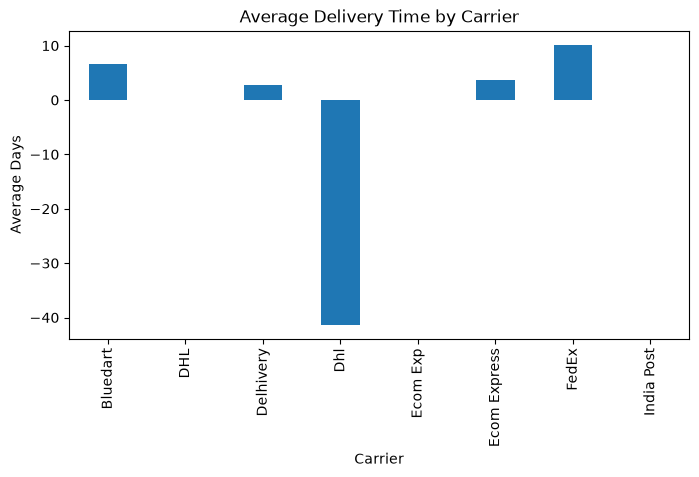

In [119]:
import matplotlib.pyplot as plt

carrier_result["Average_Days"].plot(kind="bar", figsize=(8, 4))

plt.title("Average Delivery Time by Carrier")
plt.xlabel("Carrier")
plt.ylabel("Average Days")
plt.show()

# 9. Create inventory sell-through and stockout indicators when inventory snapshots are available.

In [120]:
sales = df[df["Event_Type"] == "purchase"].copy()

sales.head()

,Order_ID,Line_ID,Event_Version,Customer_ID,Master_Customer_ID,Transaction_ID,Visitor_ID,Session_ID,Event_Type,Order_TS,...,Event_Review,Shipment_Review,Delivery_Review,Gross_Sales,Net_Sales,Month,Order_Value,First_Purchase_Month,Lead_Time,On_Time
18,ORD-1228,L1,1,CUST-037,CUST-037,TXN-46643560,VIS-47918,SES-353052,purchase,2026-07-20 21:19:00+00:00,...,False,False,False,-0.0,-599.8,2026-07,-599.8,2026-07,NaN,False
19,ORD-1091,L1,1,CUST-066,CUST-066,TXN-78644309,VIS-37991,SES-603724,purchase,2026-03-03 09:56:00+00:00,...,False,False,False,0.0,0.0,2026-03,0.0,2026-03,NaN,False
28,ORD-1034,L1,1,CUST-045,CUST-045,TXN42707660,VIS-16648,SES-565198,purchase,2026-04-12 20:49:00+00:00,...,False,False,False,0.0,-99.9,2026-04,-99.9,2026-04,NaN,False
30,ORD-1187,L2,1,CUST-020,NaN,TXN-15026701,VIS-58102,SES-414786,purchase,2026-03-19 02:25:00+00:00,...,False,False,False,799.0,799.0,2026-03,799.0,2026-03,2.6875,True
36,ORD-1096,L3,1,CUST-120,NaN,TXN43948523,VIS-69151,SES-218877,purchase,2026-04-01 00:15:00+00:00,...,True,False,False,24.0,24.0,2026-04,24.0,2026-04,NaN,False


In [121]:
sold = sales.groupby("SKU")["Qty"].sum()

stock = df.groupby("SKU")["Stock_Quantity"].max()

inventory = pd.DataFrame({
    "Units_Sold": sold,
    "Stock_Quantity": stock
})

inventory["Sell_Through (%)"] = (
    inventory["Units_Sold"] /
    (inventory["Units_Sold"] + inventory["Stock_Quantity"])
) * 100

display(inventory.round(2))

,Units_Sold,Stock_Quantity,Sell_Through (%)
SKU,,,
BOTTLE-1L,2.0,12.0,14.29
EARBUD-PRO,2.0,300.0,0.66
JEANS_32,5.0,150.0,3.23
LAMP_DESK,3.0,60.0,4.76
MUG_BLK,3.0,3.0,50.00
NOTEBOOK-A5,1.0,60.0,1.64
PEN-GEL,3.0,300.0,0.99
PHONECASE_X,10.0,150.0,6.25
SHOE_RUN_9,6.0,150.0,3.85


In [122]:
inventory["Stockout"] = inventory["Stock_Quantity"] <= 0

display(inventory)

,Units_Sold,Stock_Quantity,Sell_Through (%),Stockout
SKU,,,,
BOTTLE-1L,2.0,12.0,14.285714,False
EARBUD-PRO,2.0,300.0,0.662252,False
JEANS_32,5.0,150.0,3.225806,False
LAMP_DESK,3.0,60.0,4.761905,False
MUG_BLK,3.0,3.0,50.000000,False
NOTEBOOK-A5,1.0,60.0,1.639344,False
PEN-GEL,3.0,300.0,0.990099,False
PHONECASE_X,10.0,150.0,6.250000,False
SHOE_RUN_9,6.0,150.0,3.846154,False


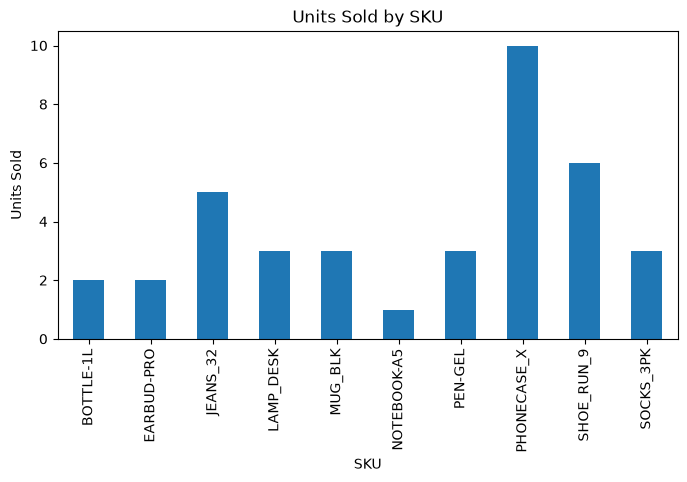

In [123]:
import matplotlib.pyplot as plt

inventory["Units_Sold"].head(10).plot(kind="bar", figsize=(8, 4))

plt.title("Units Sold by SKU")
plt.xlabel("SKU")
plt.ylabel("Units Sold")
plt.show()

# 10. Compute payment authorization, capture, and failure rates by method and channel.

Payment Summary:
  Payment_Method Sales_Channel Payment_Status  Count
0           card      In-Store        pending      1
1           card   Marketplace       captured      2
2           card   Marketplace         failed      2
3           card    Mobile App         failed      1
4           card    Mobile App        pending      1
5           card    Mobile_App         failed      1
6           card        Online     authorized      1
7           card        Online         failed      1
8           card        Online        pending      1
9           card         Store     authorized      1

Payment Rates:
      Payment_Method Sales_Channel Payment_Status  Count  Total        Rate
0               card      In-Store        pending      1      1  100.000000
1               card   Marketplace       captured      2      4   50.000000
2               card   Marketplace         failed      2      4   50.000000
3               card    Mobile App         failed      1      2   50.000000
4   

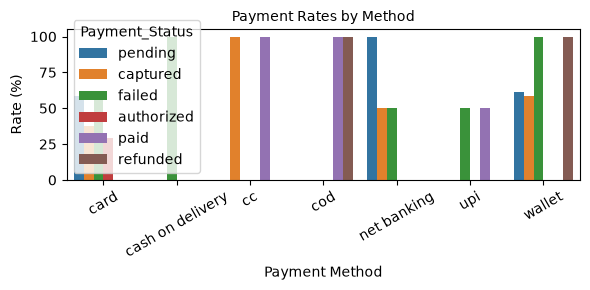


Payment Rates by Channel:
   Sales_Channel Payment_Status        Rate
0       In-Store        pending  100.000000
1    Marketplace       captured   50.000000
2    Marketplace         failed   50.000000
3     Mobile App         failed   50.000000
4     Mobile App        pending   50.000000
5     Mobile_App         failed  100.000000
6         Online     authorized   33.333333
7         Online         failed   33.333333
8         Online        pending   33.333333
9          Store     authorized   25.000000
10         Store       captured   25.000000
11         Store        pending   50.000000
12   Marketplace         failed  100.000000
13    Mobile App       captured  100.000000
14    Mobile_App           paid  100.000000
15        Online           paid  100.000000
16        Online       refunded  100.000000
17         Store           paid  100.000000
18           App       captured   50.000000
19           App         failed   50.000000
20        Online        pending  100.000000
21   

In [124]:
# Count payments by method and channel
payment_summary = df.groupby(
    ["Payment_Method", "Sales_Channel", "Payment_Status"]
).size().reset_index(name="Count")

print("Payment Summary:")
print(payment_summary.head(10))

# Calculate total payments for each method and channel
payment_summary["Total"] = payment_summary.groupby(
    ["Payment_Method", "Sales_Channel"]
)["Count"].transform("sum")

# Calculate payment rate
payment_summary["Rate"] = (
    payment_summary["Count"] / payment_summary["Total"] * 100
)

# Display payment rates
print("\nPayment Rates:")
print(payment_summary)

# Create a small chart
plt.figure(figsize=(6, 3))

sns.barplot(
    data=payment_summary,
    x="Payment_Method",
    y="Rate",
    hue="Payment_Status",
    errorbar=None
)

plt.title("Payment Rates by Method", fontsize=10)
plt.xlabel("Payment Method")
plt.ylabel("Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Display rates by sales channel
print("\nPayment Rates by Channel:")
print(payment_summary[
    ["Sales_Channel", "Payment_Status", "Rate"]
])


# 11. Estimate customer lifetime value using an explicitly documented historical method.

In [125]:
# Select purchase records
sales = df[df["Event_Type"] == "purchase"]

# Calculate total spending for each customer
clv = sales.groupby("Customer_ID")["Amount"].sum()

# Show the top 10 customers
print("Top 10 Customers by Historical CLV:")
print(clv.sort_values(ascending=False).head(10))

# Calculate average CLV
print("Average Historical CLV:", round(clv.mean(), 2))


Top 10 Customers by Historical CLV:
Customer_ID
CUST-119    10748.15
CUST-003     7078.00
CUST-018     6050.04
CUST-092     3361.88
CUST-037     2831.06
CUST-061     1804.40
CUST-045     1060.94
CUST-949      942.82
CUST-020      942.82
CUST-036      801.40
Name: Amount, dtype: float64
Average Historical CLV: 1095.25


# 12. Build regional sales summaries using standardized geography.

Country        State      
In             Odisha         10748.15
India          Od              7078.00
Ind            Tn              6050.04
               Karnataka       3361.88
               Maharashtra     2831.06
India          Ka              1931.84
In             Maharashtra     1130.86
India          Odisha          1060.94
               Delhi            942.82
Ind            New Delhi        942.82
India          New Delhi        423.74
               Maharashtra      165.90
In             Karnataka        159.30
Gb             England          138.87
De             Berlin           124.65
United States  Ny               114.70
Germany        Berlin            25.92
               Be                 4.96
United States  New York           2.16
In             Orissa             0.00
Deu            Berlin             0.00
In             Mh                 0.00
India          Karnataka          0.00
               Mh                 0.00
               Tamil Nadu         0.0

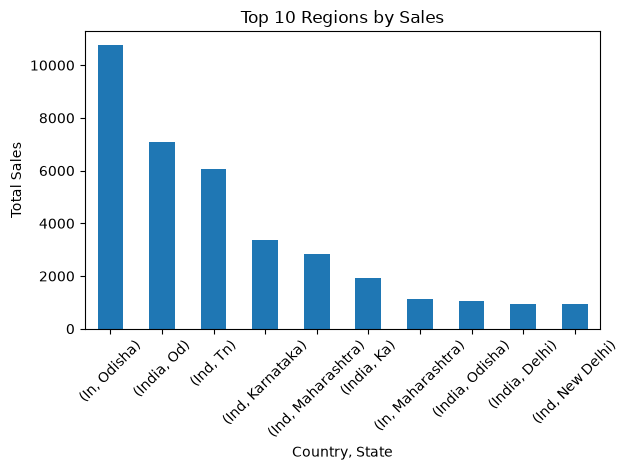

In [126]:
# Select purchase records
sales = df[df["Event_Type"] == "purchase"].copy()

# Standardize country and state names
sales["Country"] = sales["Country"].str.strip().str.title()
sales["State"] = sales["State"].str.strip().str.title()

# Calculate sales by country and state
regional_sales = sales.groupby(["Country", "State"])["Amount"].sum()

# Show the results
print(regional_sales.sort_values(ascending=False))

# Plot regional sales
regional_sales.sort_values(ascending=False).head(10).plot(
    kind="bar",
    title="Top 10 Regions by Sales",
    ylabel="Total Sales",
    xlabel="Country, State",
    rot=45
)

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()


# 13. Detect sales, discount, refund, and payment anomalies against historical baselines.


Unusual values in Amount
    Order_ID    Amount
76  ORD-1113  10748.15


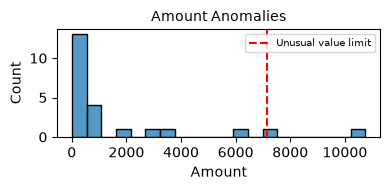


Unusual values in Discount
     Order_ID  Discount
18   ORD-1228     599.8
119  ORD-1113     359.6


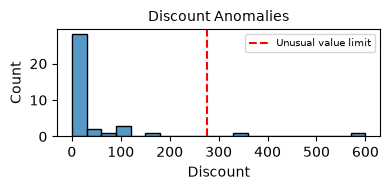


Unusual values in Refund_Amount
    Order_ID  Refund_Amount
76  ORD-1113        5374.07


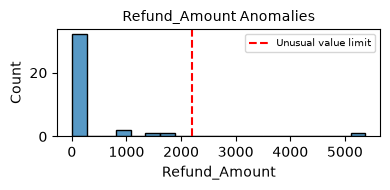


Unusual Payment Amounts:
    Order_ID Payment_Status    Amount
76  ORD-1113        pending  10748.15


In [127]:
# Convert columns to numbers
cols = ["Amount", "Discount", "Refund_Amount"]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Find unusual values
for col in cols:

    average = df[col].mean()
    std = df[col].std()

    unusual = df[df[col] > average + 2 * std]

    print("\nUnusual values in", col)
    print(unusual[["Order_ID", col]].head(10))

    # Show a small chart
    plt.figure(figsize=(4, 2))
    sns.histplot(df[col].dropna(), bins=20)
    plt.axvline(average + 2 * std, color="red",
                linestyle="--", label="Unusual value limit")

    plt.title(col + " Anomalies", fontsize=10)
    plt.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

# Check unusual payment amounts
payments = df[df["Payment_Status"].notna()]
average = payments["Amount"].mean()
std = payments["Amount"].std()

print("\nUnusual Payment Amounts:")
print(payments[payments["Amount"] > average + 2 * std]
      [["Order_ID", "Payment_Status", "Amount"]].head(10))


# 14. Calculate net revenue after discounts, refunds, and shipping adjustments using agreed definitions.

Total Net Revenue: 25025.540000000005
    Order_ID  Net_Revenue
18  ORD-1228      2231.26
19  ORD-1091         0.00
28  ORD-1034      1110.04
30  ORD-1187       942.82
36  ORD-1096        25.92
39  ORD-1129     -1062.00
50  ORD-1271       131.00
76  ORD-1113      5374.08
91  ORD-1266         7.87
96  ORD-1061      1530.99


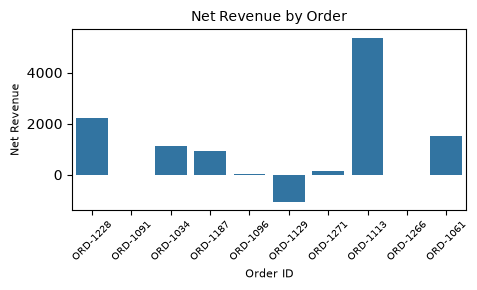

In [128]:
# Convert columns to numbers
cols = ["Amount", "Discount", "Refund_Amount", "Shipping_Cost"]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Select purchase records
sales = df[df["Event_Type"] == "purchase"].copy()

# Calculate net revenue
sales["Net_Revenue"] = (
    sales["Amount"]
    - sales["Discount"]
    - sales["Refund_Amount"]
    + sales["Shipping_Cost"]
)

# Display total net revenue
print("Total Net Revenue:", sales["Net_Revenue"].sum())

# Display first 10 records
print(sales[["Order_ID", "Net_Revenue"]].head(10))

# Create a small chart
plt.figure(figsize=(5, 3))
sns.barplot(data=sales.head(10), x="Order_ID", y="Net_Revenue",
            errorbar=None)

plt.title("Net Revenue by Order", fontsize=10)
plt.xlabel("Order ID", fontsize=8)
plt.ylabel("Net Revenue", fontsize=8)
plt.xticks(rotation=45, fontsize=7)
plt.tight_layout()
plt.show()


# 15. Create privacy-safe dashboard extracts with customer-level identifiers removed or tokenized.

  Product_Category    Amount
0      Accessories    448.04
1          Apparel  21619.09
2      Electronics  13385.64
3         Footwear    255.65
4   Home & Kitchen   1073.77
5           Sports     25.92
6       Stationery    430.50


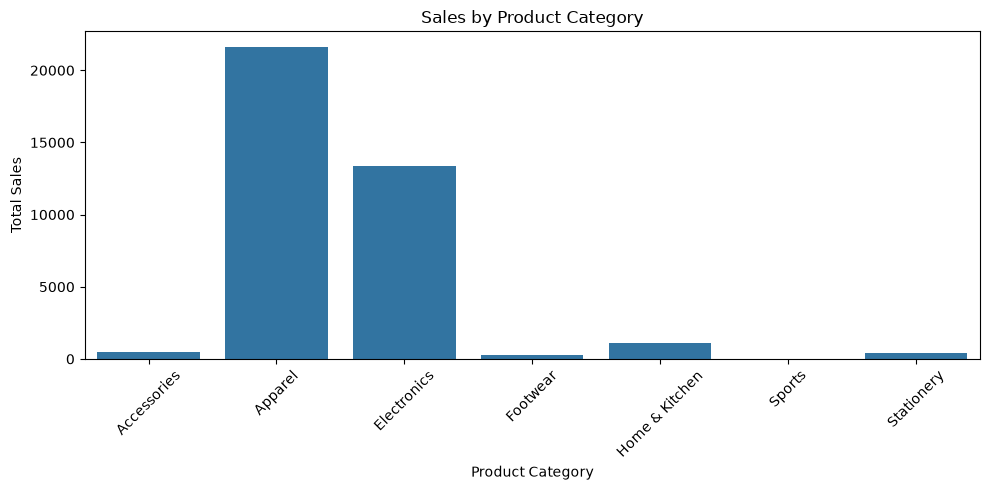

In [129]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



# Remove customer personal information
df = df.drop(columns=[
    "Customer_ID",
    "Master_Customer_ID",
    "Email",
    "Phone_Number",
    "Visitor_ID",
    "Session_ID",
    "Tracking_ID"
], errors="ignore")

# Select purchase records
sales = df[df["Event_Type"] == "purchase"].copy()

# Convert Amount to numeric values
sales["Amount"] = pd.to_numeric(sales["Amount"], errors="coerce")

# Create a summary by product category
summary = sales.groupby("Product_Category")["Amount"].sum().reset_index()

# Replace missing sales values with 0
summary["Amount"] = summary["Amount"].fillna(0)

# Save privacy-safe dashboard data
summary.to_csv("privacy_safe_dashboard.csv", index=False)

# Display the summary
print(summary)

# Create a sales chart
plt.figure(figsize=(10, 5))
sns.barplot(data=summary, x="Product_Category", y="Amount")

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 16. Compare product performance across campaign, device, and acquisition channel where data supports it.

Product Sales by Campaign:
             Product Campaign_ID    Amount
0        A5 Notebook     CMP-001    159.30
1  Black Ceramic Mug     CMP-001      4.96
2  Black Ceramic Mug     CMP-006      0.00
3       Cotton Tee L     CMP-001      0.00
4       Cotton Tee L     CMP-007   1744.22
5       Cotton Tee M     CMP-001    942.82
6       Cotton Tee M     CMP-004  10748.15
7       Gel Pen Pack     CMP-001    143.76
8       Gel Pen Pack     CMP-002      0.00
9       Gel Pen Pack     CMP-007    127.44

Product Sales by Device:
             Product   Device    Amount
0  Black Ceramic Mug   Tablet      0.00
1  Black Ceramic Mug  unknown      4.96
2       Cotton Tee L  DESKTOP   1744.22
3       Cotton Tee M   Tablet  10748.15
4       Cotton Tee M  desktop    942.82
5       Gel Pen Pack  Desktop    127.44
6       Gel Pen Pack   Mobile      0.00
7       Gel Pen Pack   Tablet    143.76
8       Gel Pen Pack  desktop      0.00
9       Gel Pen Pack  unknown      0.00

Product Sales by Acquisition Chan

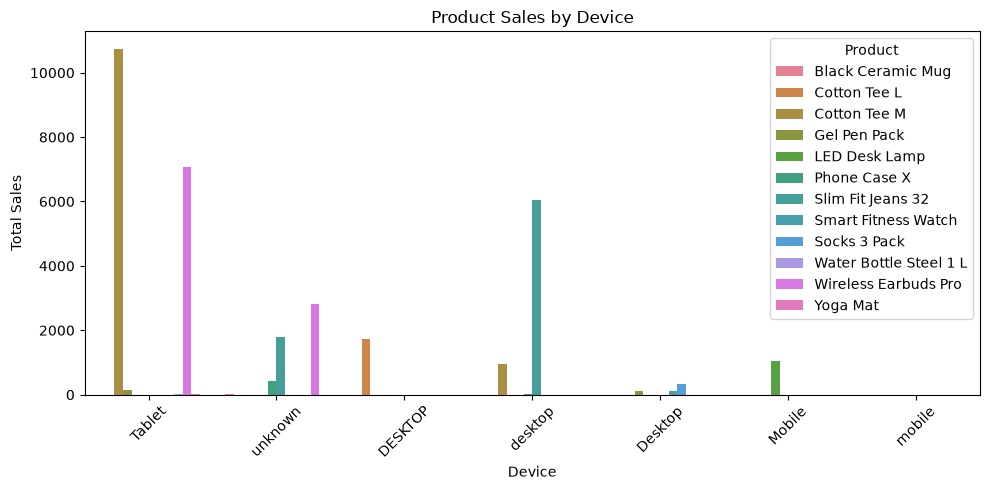

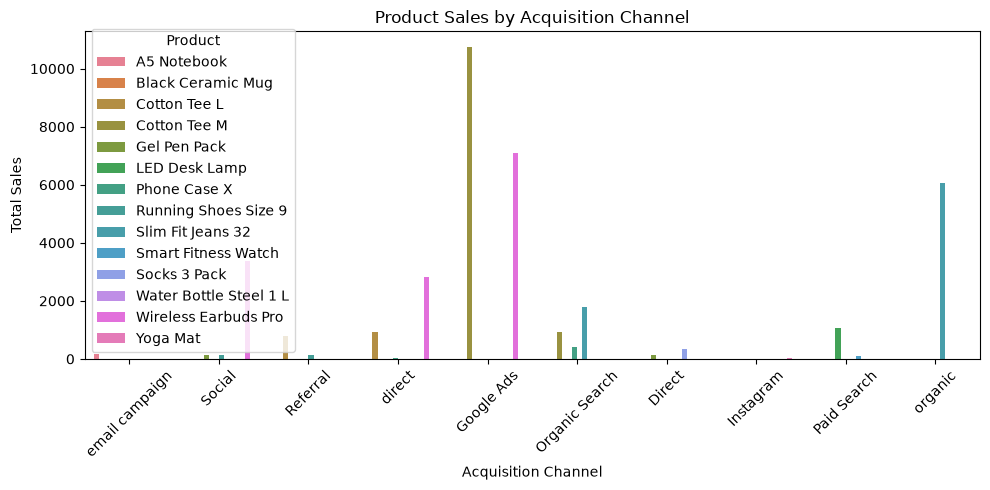

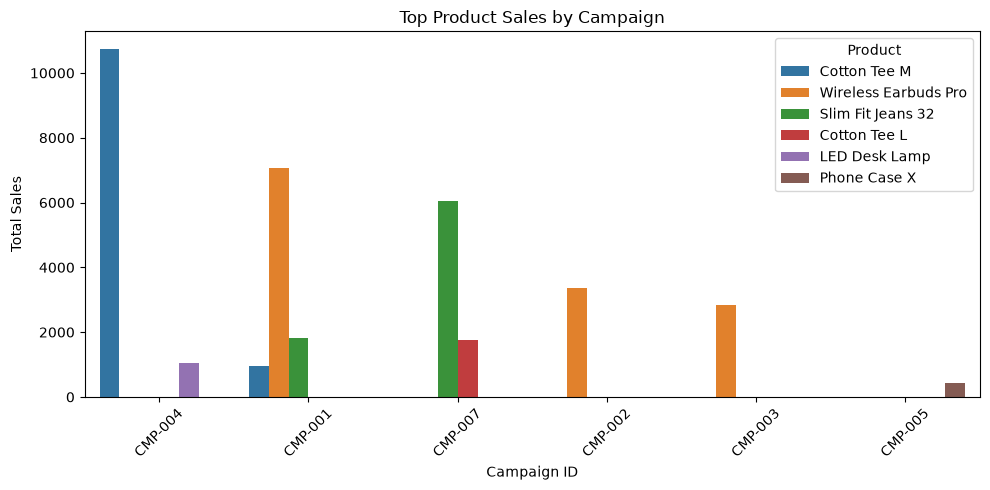

In [130]:


# Select purchase records
sales = df[df["Event_Type"] == "purchase"].copy()

# Convert Amount to numeric
sales["Amount"] = pd.to_numeric(sales["Amount"], errors="coerce")

# Remove rows with missing product or sales amount
sales = sales.dropna(subset=["Product", "Amount"])

# 1. Product sales by campaign
campaign_sales = sales.groupby(
    ["Product", "Campaign_ID"]
)["Amount"].sum().reset_index()

print("Product Sales by Campaign:")
print(campaign_sales.head(10))

# 2. Product sales by device
device_sales = sales.groupby(
    ["Product", "Device"]
)["Amount"].sum().reset_index()

print("\nProduct Sales by Device:")
print(device_sales.head(10))

# 3. Product sales by acquisition channel
channel_sales = sales.groupby(
    ["Product", "Acquisition_Channel"]
)["Amount"].sum().reset_index()

print("\nProduct Sales by Acquisition Channel:")
print(channel_sales.head(10))

# Plot product sales by device
plt.figure(figsize=(10, 5))
sns.barplot(data=device_sales, x="Device", y="Amount", hue="Product",
            errorbar=None)
plt.title("Product Sales by Device")
plt.xlabel("Device")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot product sales by acquisition channel
plt.figure(figsize=(10, 5))
sns.barplot(data=channel_sales, x="Acquisition_Channel",
            y="Amount", hue="Product", errorbar=None)
plt.title("Product Sales by Acquisition Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot product sales by campaign
top_campaigns = campaign_sales.sort_values(
    "Amount", ascending=False
).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_campaigns, x="Campaign_ID", y="Amount", hue="Product",
            errorbar=None)
plt.title("Top Product Sales by Campaign")
plt.xlabel("Campaign ID")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
